# Proyecto de Minería de Datos - Cine Éxito

## Pregunta objetivo

¿Qué características de las películas se asocian a un mayor éxito en taquilla, de manera que los administradores del cine puedan decidir qué títulos programar para asegurar una alta demanda?

## Fuentes

1. IMDb Dataset
2. TMDB Movies Dataset

## Integrantes

- Santiago Ceballos
- Jhon Harold Ramirez
- Juan Esteban Ceballos
- Erik Torres

Este Notebook corresponde a la etapa de adquisición y preparación inicial de los datos.

## 1. Importación de librerías

Se comienza importando las librerías necesarias donde se descarguen y localicen los datos para leerlos y preparar las fuentes de datos.
Principalmente se usa “Pandas” para manipular los datasets, también se usa “os” el cual ayuda a localizar archivos dentro de las carpetas y “Kagglehub” para obtener las fuentes.
Este Notebook está hecho para ejecutarse desde el principio en Google Colab.


In [1]:

# 1. IMPORTACIÓN DE LIBRERÍAS


import pandas as pd
import numpy as np
import os
import kagglehub

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Descarga y localización de la fuente IMDb

Se intenta obtener IMDb mediante KaggleHub. Si KaggleHub presenta una referencia de versión que ya no existe, el Notebook utiliza como respaldo los archivos oficiales de IMDb (`title.basics.tsv.gz` y `title.ratings.tsv.gz`). De esta forma no se depende de una versión histórica de Kaggle para ejecutar el proyecto en Google Colab.


In [2]:
# ============================================================
# 2. DESCARGA Y LOCALIZACIÓN DE IMDb
# ============================================================

# El proyecto utiliza IMDb como una de sus fuentes principales.
# Se intenta primero reutilizar archivos que ya estén disponibles
# en la caché de Colab/KaggleHub.
#
# Si KaggleHub presenta un error de versión antigua (por ejemplo 404),
# se utiliza como respaldo la fuente oficial de IMDb, que publica
# los mismos archivos TSV de títulos y calificaciones.

NOMBRE_BASICS = "title.basics.tsv"
NOMBRE_RATINGS = "title.ratings.tsv"
HANDLE_IMDB = "ashirwadsangwan/imdb-dataset"

ruta_imdb_basics = None
ruta_imdb_ratings = None

# ------------------------------------------------------------
# 1) Buscar primero archivos ya descargados localmente
# ------------------------------------------------------------

carpetas_busqueda_imdb = [
    "/content",
    os.path.expanduser("~/.cache/kagglehub")
]

for carpeta_base in carpetas_busqueda_imdb:
    if not os.path.isdir(carpeta_base):
        continue

    for raiz, carpetas, archivos in os.walk(carpeta_base):
        if NOMBRE_BASICS in archivos and ruta_imdb_basics is None:
            ruta_imdb_basics = os.path.join(raiz, NOMBRE_BASICS)

        if NOMBRE_RATINGS in archivos and ruta_imdb_ratings is None:
            ruta_imdb_ratings = os.path.join(raiz, NOMBRE_RATINGS)

        if ruta_imdb_basics and ruta_imdb_ratings:
            break

    if ruta_imdb_basics and ruta_imdb_ratings:
        break

# ------------------------------------------------------------
# 2) Si ya existen ambos archivos, reutilizarlos
# ------------------------------------------------------------

if ruta_imdb_basics and ruta_imdb_ratings:
    ruta_imdb = os.path.dirname(ruta_imdb_basics)
    print("IMDb ya está disponible localmente.")
    print("No se realizará ninguna descarga de IMDb.")

else:
    print("No se encontraron ambos archivos IMDb localmente.")
    errores_imdb = []

    # --------------------------------------------------------
    # 3) Intentar KaggleHub sin fijar una versión antigua
    # --------------------------------------------------------
    try:
        print("Intentando obtener IMDb desde KaggleHub...")

        carpeta_imdb_kaggle = "/content/imdb_kaggle"
        os.makedirs(carpeta_imdb_kaggle, exist_ok=True)

        ruta_imdb_descarga = kagglehub.dataset_download(
            HANDLE_IMDB,
            output_dir=carpeta_imdb_kaggle,
            force_download=True
        )

        # Localizar los dos archivos después de la descarga.
        for raiz, carpetas, archivos in os.walk(ruta_imdb_descarga):
            if NOMBRE_BASICS in archivos and ruta_imdb_basics is None:
                ruta_imdb_basics = os.path.join(raiz, NOMBRE_BASICS)

            if NOMBRE_RATINGS in archivos and ruta_imdb_ratings is None:
                ruta_imdb_ratings = os.path.join(raiz, NOMBRE_RATINGS)

            if ruta_imdb_basics and ruta_imdb_ratings:
                break

    except Exception as error_kaggle_imdb:
        errores_imdb.append(
            "KaggleHub -> "
            f"{type(error_kaggle_imdb).__name__}: {error_kaggle_imdb}"
        )
        print("KaggleHub no pudo obtener IMDb.")
        print("Se utilizará la fuente oficial de IMDb como respaldo.")

    # --------------------------------------------------------
    # 4) Respaldo: archivos oficiales publicados por IMDb
    # --------------------------------------------------------
    if not (ruta_imdb_basics and ruta_imdb_ratings):
        print("Descargando los archivos oficiales de IMDb...")

        import urllib.request

        carpeta_imdb_oficial = "/content/imdb_oficial"
        os.makedirs(carpeta_imdb_oficial, exist_ok=True)

        url_basics = "https://datasets.imdbws.com/title.basics.tsv.gz"
        url_ratings = "https://datasets.imdbws.com/title.ratings.tsv.gz"

        archivo_basics_gz = os.path.join(
            carpeta_imdb_oficial,
            "title.basics.tsv.gz"
        )
        archivo_ratings_gz = os.path.join(
            carpeta_imdb_oficial,
            "title.ratings.tsv.gz"
        )

        try:
            if not os.path.isfile(archivo_basics_gz):
                urllib.request.urlretrieve(url_basics, archivo_basics_gz)

            if not os.path.isfile(archivo_ratings_gz):
                urllib.request.urlretrieve(url_ratings, archivo_ratings_gz)

            # Pandas puede leer directamente los archivos comprimidos,
            # por lo que conservamos las rutas .gz como fuente de lectura.
            ruta_imdb_basics = archivo_basics_gz
            ruta_imdb_ratings = archivo_ratings_gz
            ruta_imdb = carpeta_imdb_oficial

            print("Archivos oficiales de IMDb obtenidos correctamente.")

        except Exception as error_oficial_imdb:
            errores_imdb.append(
                "IMDb oficial -> "
                f"{type(error_oficial_imdb).__name__}: {error_oficial_imdb}"
            )

    # --------------------------------------------------------
    # 5) Validación final
    # --------------------------------------------------------
    if not (ruta_imdb_basics and ruta_imdb_ratings):
        detalle = "\n".join(errores_imdb)
        raise RuntimeError(
            "No se pudieron obtener los archivos necesarios de IMDb.\n\n"
            "Se intentó utilizar KaggleHub y, como respaldo, la fuente oficial "
            "de IMDb.\n\n"
            f"Detalles técnicos:\n{detalle}"
        )

print("\nArchivo IMDb Basics encontrado:")
print(ruta_imdb_basics)

print("\nArchivo IMDb Ratings encontrado:")
print(ruta_imdb_ratings)


No se encontraron ambos archivos IMDb localmente.
Intentando obtener IMDb desde KaggleHub...
KaggleHub no pudo obtener IMDb.
Se utilizará la fuente oficial de IMDb como respaldo.
Descargando los archivos oficiales de IMDb...
Archivos oficiales de IMDb obtenidos correctamente.

Archivo IMDb Basics encontrado:
/content/imdb_oficial/title.basics.tsv.gz

Archivo IMDb Ratings encontrado:
/content/imdb_oficial/title.ratings.tsv.gz


## 3. Revisión de la estructura de IMDb
Antes de proceder a cargar los datasets se revisa los encabezados para comprobar que columnas hay disponibles, a su vez se carga una muestra de “title.basics” para poder observar una estructura inicial de los registros.


In [3]:

# 3. REVISIÓN DE LA ESTRUCTURA DE IMDb


imdb_basics_header = pd.read_csv(
    ruta_imdb_basics,
    sep="\t",
    nrows=0
)

imdb_ratings_header = pd.read_csv(
    ruta_imdb_ratings,
    sep="\t",
    nrows=0
)

print("COLUMNAS IMDb - title.basics")
print(imdb_basics_header.columns.tolist())

print("\nCOLUMNAS IMDb - title.ratings")
print(imdb_ratings_header.columns.tolist())

# Muestra inicial de title.basics
imdb_basics_muestra = pd.read_csv(
    ruta_imdb_basics,
    sep="\t",
    nrows=5,
    na_values="\\N"
)

print("\nMuestra inicial de IMDb title.basics:")
display(imdb_basics_muestra)

print("Dimensiones de la muestra:")
print(imdb_basics_muestra.shape)

COLUMNAS IMDb - title.basics
['tconst', 'titleType', 'primaryTitle', 'originalTitle', 'isAdult', 'startYear', 'endYear', 'runtimeMinutes', 'genres']

COLUMNAS IMDb - title.ratings
['tconst', 'averageRating', 'numVotes']

Muestra inicial de IMDb title.basics:


,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894,NaN,1,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892,NaN,5,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892,NaN,5,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892,NaN,12,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893,NaN,1,Short


Dimensiones de la muestra:
(5, 9)


## 4. Carga de la información básica de películas IMDb

Solo se selecciona las columnas necesarias de “title.basics”
El campo “tconst” será un identificador de cada título para luego usarlo al integrar la información de ratings.


In [4]:

# 4. CARGA DE IMDb TITLE.BASICS


columnas_imdb = [
    "tconst",
    "titleType",
    "primaryTitle",
    "startYear",
    "runtimeMinutes",
    "genres"
]

imdb_peliculas = pd.read_csv(
    ruta_imdb_basics,
    sep="\t",
    usecols=columnas_imdb,
    na_values="\\N"
)

print("Datos IMDb title.basics cargados correctamente.")
print("Filas:", len(imdb_peliculas))
print("Columnas:", imdb_peliculas.shape[1])

display(imdb_peliculas.head())

/tmp/ipykernel_808/1599500818.py:13: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  imdb_peliculas = pd.read_csv(


Datos IMDb title.basics cargados correctamente.
Filas: 12902085
Columnas: 6


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,1894.0,1.0,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,1892.0,5.0,"Animation,Short"
2,tt0000003,short,Poor Pierrot,1892.0,5.0,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,1892.0,12.0,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,1893.0,1.0,Short


## 5. Carga de ratings de IMDb

Cargamos el archivo “title.ratings.tsv” en donde están las calificaciones promedio y la cantidad de votos de las películas, luego usamos tconst como identificador para poder relacionar los datos con información básica de las películas

In [5]:

# 5. CARGA DE IMDb TITLE.RATINGS

imdb_ratings = pd.read_csv(
    ruta_imdb_ratings,
    sep="\t",
    usecols=["tconst", "averageRating", "numVotes"],
    na_values="\\N"
)

print("Datos IMDb ratings cargados correctamente.")
print("Filas:", len(imdb_ratings))
print("Columnas:", imdb_ratings.shape[1])

display(imdb_ratings.head())

print("Dimensiones de IMDb Ratings:", imdb_ratings.shape)

Datos IMDb ratings cargados correctamente.
Filas: 1726141
Columnas: 3


,tconst,averageRating,numVotes
0,tt0000001,5.7,2238
1,tt0000002,5.4,327
2,tt0000003,6.4,2401
3,tt0000004,5.0,203
4,tt0000005,6.2,3104


Dimensiones de IMDb Ratings: (1726141, 3)


## 6. Filtrado de películas en IMDb

En IMDb se manejan varios tipos de títulos aunque este proyecto esta enfocado en las peliculas y solo se tienen en cuenta los registros que están como movie en la columna “titleType”

In [6]:
# ============================================================
# 6. FILTRAR SOLAMENTE PELÍCULAS
# ============================================================

imdb_peliculas = imdb_peliculas[
    imdb_peliculas["titleType"] == "movie"
].copy()

print("Cantidad de películas IMDb:", len(imdb_peliculas))

display(imdb_peliculas.head())

Cantidad de películas IMDb: 760683


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres
8,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance
144,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport"
498,tt0000502,movie,Bohemios,1905.0,100.0,NaN
570,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography"
587,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama


## 7. Integración de las tablas de IMDb

Se unen title.basics y title.ratings usando la columna tconst que tienen en común. Se hace un inner merge para quedarse solo con las películas que tienen información en las dos tablas y se compara la cantidad de filas antes y después de la unión para llevar un control del proceso

In [7]:
# ============================================================
# 7. CRUCE IMDb BASICS + IMDb RATINGS
# ============================================================

filas_imdb_antes = len(imdb_peliculas)

imdb = pd.merge(
    imdb_peliculas,
    imdb_ratings,
    on="tconst",
    how="inner"
)

filas_imdb_despues = len(imdb)

print("Filas de películas antes:", filas_imdb_antes)
print("Filas después de agregar ratings:", filas_imdb_despues)

print("\nDimensiones del dataset IMDb integrado:", imdb.shape)

display(imdb.head())

Filas de películas antes: 760683
Filas después de agregar ratings: 350804

Dimensiones del dataset IMDb integrado: (350804, 8)


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres,averageRating,numVotes
0,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance,5.3,240
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport",5.3,618
2,tt0000502,movie,Bohemios,1905.0,100.0,NaN,3.6,28
3,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography",6.0,1102
4,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama,5.1,43


## 8. Descarga y localización de la fuente TMDB

Se intenta obtener el archivo `TMDB_movie_dataset_v11.csv` mediante el identificador actual del dataset en Kaggle, sin fijar una versión numérica. Si KaggleHub no puede descargarlo, se ofrece una carga manual desde Colab para evitar que una versión antigua de Kaggle bloquee todo el Notebook.


In [8]:
# ============================================================
# 8. DESCARGA Y LOCALIZACIÓN DE TMDB
# ============================================================

# Se utiliza el identificador actual del dataset de TMDB.
# No se fija una versión numérica para evitar referencias a versiones
# antiguas que puedan dejar de estar disponibles en Kaggle.

NOMBRE_ARCHIVO_TMDB = "TMDB_movie_dataset_v11.csv"
HANDLE_TMDB = "asaniczka/tmdb-movies-dataset-2023-930k-movies"

ruta_tmdb_archivo = None

# ------------------------------------------------------------
# 1) Buscar primero una copia local existente
# ------------------------------------------------------------

carpetas_tmdb_busqueda = [
    "/content",
    os.path.expanduser("~/.cache/kagglehub")
]

archivos_tmdb_existentes = []

for carpeta_base in carpetas_tmdb_busqueda:
    if not os.path.isdir(carpeta_base):
        continue

    for raiz, carpetas, archivos in os.walk(carpeta_base):
        if NOMBRE_ARCHIVO_TMDB in archivos:
            archivos_tmdb_existentes.append(
                os.path.join(raiz, NOMBRE_ARCHIVO_TMDB)
            )

if archivos_tmdb_existentes:
    ruta_tmdb_archivo = max(
        archivos_tmdb_existentes,
        key=os.path.getmtime
    )
    ruta_tmdb = os.path.dirname(ruta_tmdb_archivo)
    print("TMDB ya está disponible localmente.")
    print("No se realizará ninguna descarga.")

else:
    print("No se encontró TMDB localmente.")
    errores_descarga = []

    # --------------------------------------------------------
    # 2) Intentar KaggleHub usando el handle sin versión fija
    # --------------------------------------------------------
    try:
        print("Intentando descargar TMDB desde KaggleHub...")

        carpeta_tmdb_kaggle = "/content/tmdb_kaggle"
        os.makedirs(carpeta_tmdb_kaggle, exist_ok=True)

        ruta_descarga_tmdb = kagglehub.dataset_download(
            HANDLE_TMDB,
            path=NOMBRE_ARCHIVO_TMDB,
            output_dir=carpeta_tmdb_kaggle,
            force_download=True
        )

        if os.path.isfile(ruta_descarga_tmdb):
            ruta_tmdb_archivo = ruta_descarga_tmdb
        else:
            for raiz, carpetas, archivos in os.walk(ruta_descarga_tmdb):
                if NOMBRE_ARCHIVO_TMDB in archivos:
                    ruta_tmdb_archivo = os.path.join(
                        raiz, NOMBRE_ARCHIVO_TMDB
                    )
                    break

    except Exception as error_descarga:
        errores_descarga.append(
            "KaggleHub -> "
            f"{type(error_descarga).__name__}: {error_descarga}"
        )
        print("KaggleHub no pudo obtener TMDB automáticamente.")

    # --------------------------------------------------------
    # 3) Autenticación opcional: solo una vez
    # --------------------------------------------------------
    if ruta_tmdb_archivo is None:
        print("\nSe intentará autenticar KaggleHub una sola vez.")

        try:
            kagglehub.login()
            print("Autenticación completada.")

            ruta_descarga_tmdb = kagglehub.dataset_download(
                HANDLE_TMDB,
                path=NOMBRE_ARCHIVO_TMDB,
                output_dir="/content/tmdb_kaggle",
                force_download=True
            )

            if os.path.isfile(ruta_descarga_tmdb):
                ruta_tmdb_archivo = ruta_descarga_tmdb
            else:
                for raiz, carpetas, archivos in os.walk(ruta_descarga_tmdb):
                    if NOMBRE_ARCHIVO_TMDB in archivos:
                        ruta_tmdb_archivo = os.path.join(
                            raiz, NOMBRE_ARCHIVO_TMDB
                        )
                        break

        except Exception as error_autenticacion:
            errores_descarga.append(
                "Autenticación -> "
                f"{type(error_autenticacion).__name__}: {error_autenticacion}"
            )

    # --------------------------------------------------------
    # 4) Último respaldo: carga manual desde Colab
    # --------------------------------------------------------
    if ruta_tmdb_archivo is None:
        print("\nNo fue posible obtener TMDB mediante KaggleHub.")
        print("Se abrirá el selector de archivos de Google Colab.")
        print("Selecciona exactamente: TMDB_movie_dataset_v11.csv")

        try:
            from google.colab import files
            archivos_subidos = files.upload()

            if NOMBRE_ARCHIVO_TMDB not in archivos_subidos:
                raise FileNotFoundError(
                    "Debes seleccionar el archivo "
                    "TMDB_movie_dataset_v11.csv."
                )

            ruta_tmdb_archivo = os.path.join(
                "/content",
                NOMBRE_ARCHIVO_TMDB
            )

        except Exception as error_upload:
            errores_descarga.append(
                "Carga manual -> "
                f"{type(error_upload).__name__}: {error_upload}"
            )

    if ruta_tmdb_archivo is None or not os.path.isfile(ruta_tmdb_archivo):
        detalle = "\n".join(errores_descarga)
        raise RuntimeError(
            "No se pudo obtener el archivo TMDB_movie_dataset_v11.csv.\n\n"
            "Se intentó la descarga actual de KaggleHub, una autenticación "
            "única y, finalmente, la carga manual en Colab.\n\n"
            f"Detalles técnicos:\n{detalle}"
        )

    ruta_tmdb = os.path.dirname(ruta_tmdb_archivo)

print("\nRuta de TMDB:")
print(ruta_tmdb)

print("\nArchivo principal de TMDB encontrado:")
print(ruta_tmdb_archivo)


No se encontró TMDB localmente.
Intentando descargar TMDB desde KaggleHub...


100%|██████████| 641M/641M [00:06<00:00, 99.5MB/s]


Ruta de TMDB:
/content/tmdb_kaggle

Archivo principal de TMDB encontrado:
/content/tmdb_kaggle/TMDB_movie_dataset_v11.csv


## 9. Revisión de la estructura de TMDB

Antes de cargar los datos que se van a utilizar en el proyecto, se revisan los nombres de las columnas del archivo de TMDB para conocer su estructura.

In [9]:

# 9. REVISIÓN DE LA ESTRUCTURA DE TMDB


tmdb_header = pd.read_csv(
    ruta_tmdb_archivo,
    nrows=0
)

print("COLUMNAS TMDB")
print(tmdb_header.columns.tolist())

# Leer una pequeña muestra para comprobar la estructura.
tmdb_muestra = pd.read_csv(
    ruta_tmdb_archivo,
    nrows=5
)

print("\nMuestra inicial de TMDB:")
display(tmdb_muestra.head())

print("Dimensiones de la muestra:")
print(tmdb_muestra.shape)

COLUMNAS TMDB
['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'adult', 'backdrop_path', 'budget', 'homepage', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'keywords']

Muestra inicial de TMDB:


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


Dimensiones de la muestra:
(5, 24)


## 10. Carga del dataset completo de TMDB

Se carga el dataset completo utilizando la ruta local después se seleccionarán las columnas principales necesarias para el cruce y para la etapa de análisis.

In [10]:
# ============================================================
# 10. CARGA DEL DATASET COMPLETO DE TMDB
# ============================================================

tmdb = pd.read_csv(ruta_tmdb_archivo)

print("Dataset TMDB cargado correctamente.")
print("Filas:", len(tmdb))
print("Columnas:", tmdb.shape[1])

display(tmdb.head())

Dataset TMDB cargado correctamente.
Filas: 1525723
Columnas: 24


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


## 11. Selección de columnas principales de TMDB

Se conservan las siguientes columnas relacionadas con identificación, títulos, calificaciones, votos, estado, fecha de lanzamiento, ingresos, duración, presupuesto, identificador IMDb, popularidad y géneros y La columna `imdb_id` va a ser usada  como llave para relacionar TMDB con IMDb.

In [11]:

# 11. SELECCIÓN DE COLUMNAS PRINCIPALES DE TMDB

columnas_tmdb = [
    "id",
    "title",
    "vote_average",
    "vote_count",
    "status",
    "release_date",
    "revenue",
    "runtime",
    "budget",
    "imdb_id",
    "popularity",
    "genres"
]

tmdb = tmdb[columnas_tmdb].copy()

print("Columnas seleccionadas de TMDB:")
print(tmdb.columns.tolist())

print("\nDimensiones de TMDB:")
print(tmdb.shape)

display(tmdb.head())

Columnas seleccionadas de TMDB:
['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'budget', 'imdb_id', 'popularity', 'genres']

Dimensiones de TMDB:
(1525723, 12)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,160000000,tt1375666,83.952,"Action, Science Fiction, Adventure"
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,165000000,tt0816692,140.241,"Adventure, Drama, Science Fiction"
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,185000000,tt0468569,130.643,"Drama, Action, Crime, Thriller"
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,237000000,tt0499549,79.932,"Action, Adventure, Fantasy, Science Fiction"
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,220000000,tt0848228,98.082,"Science Fiction, Action, Adventure"


## 12. Normalización de los identificadores

Antes del cruce principal se normalizan los identificadores `tconst` e `imdb_id` Se van conviertir  a tipo texto y se eliminan los espacios del  inicio y del final, Esto nos ayuda a  que ambas columnas tengan un formato compatible para realizar el `merge`.

In [12]:
# ============================================================
# 12. NORMALIZACIÓN DE IDENTIFICADORES
# ============================================================

imdb["tconst"] = imdb["tconst"].astype("string").str.strip()
tmdb["imdb_id"] = tmdb["imdb_id"].astype("string").str.strip()

print("Identificadores normalizados correctamente.")

Identificadores normalizados correctamente.


## 13. Verificación de los datos antes del cruce IMDb + TMDB

Antes de realizar el cruce se registra la cantidad de filas de cada fuente y También se verifican cuántos registros tiene disponible el identificador que va a ser  utilizado como la llave de integración.

In [13]:

# 13. VERIFICACIÓN ANTES DEL CRUCE IMDb + TMDB


filas_imdb = len(imdb)
filas_tmdb = len(tmdb)

print("====================================")
print("DATOS ANTES DEL CRUCE")
print("====================================")

print("Filas IMDb:", filas_imdb)
print("Filas TMDB:", filas_tmdb)

print(
    "\nIdentificadores IMDb disponibles:",
    imdb["tconst"].notna().sum()
)

print(
    "Identificadores TMDB disponibles:",
    tmdb["imdb_id"].notna().sum()
)

DATOS ANTES DEL CRUCE
Filas IMDb: 350804
Filas TMDB: 1525723

Identificadores IMDb disponibles: 350804
Identificadores TMDB disponibles: 692433


## 14. Cruce principal entre IMDb y TMDB

Se realiza el cruce de las dos fuentes principales mediante `pd.merge()`, La columna `tconst` de IMDb se relaciona con `imdb_id` de TMDB ya que ambas representan el identificador IMDb de la película y Se utiliza un `inner merge` para que conserve solo  los registros que tienen correspondencia en las dos fuentes.

In [14]:

# 14. CRUCE PRINCIPAL IMDb + TMDB


peliculas_cruzadas = pd.merge(
    imdb,
    tmdb,
    left_on="tconst",
    right_on="imdb_id",
    how="inner",
    suffixes=("_imdb", "_tmdb")
)

print("Cruce IMDb + TMDB realizado correctamente.")

Cruce IMDb + TMDB realizado correctamente.


## 15. Verificación del resultado del cruce

Después del `merge` se verifican nuevamente el número de filas y columnas del dataset resultante Esta comparación nos permite documentar cuántos registros teníamos de cada fuente antes del cruce y cuántas películas quedaron disponibles después de integrar las dos fuentes.


In [15]:

# 15. VERIFICACIÓN DESPUÉS DEL CRUCE

filas_cruzadas = len(peliculas_cruzadas)

print("====================================")
print("RESULTADO DEL CRUCE")
print("====================================")

print("Filas IMDb antes:", filas_imdb)
print("Filas TMDB antes:", filas_tmdb)
print("Filas después del cruce:", filas_cruzadas)

print(
    "Columnas después del cruce:",
    peliculas_cruzadas.shape[1]
)

print("\nDimensiones finales:")
print(peliculas_cruzadas.shape)

display(peliculas_cruzadas.head())

print("\nColumnas del dataset cruzado:")
print(peliculas_cruzadas.columns.tolist())

RESULTADO DEL CRUCE
Filas IMDb antes: 350804
Filas TMDB antes: 1525723
Filas después del cruce: 287639
Columnas después del cruce: 20

Dimensiones finales:
(287639, 20)


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres_imdb,averageRating,numVotes,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres_tmdb
0,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance,5.3,240,356151,Miss Jerry,5.000,3,Released,1894-10-08,0,45,0,tt0000009,0.748,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport",5.3,618,147610,The Corbett-Fitzsimmons Fight,5.500,20,Released,1897-01-01,0,19,0,tt0000147,1.250,Documentary
2,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography",6.0,1102,20105,The Story of the Kelly Gang,5.397,29,Released,1906-12-26,0,70,0,tt0000574,2.160,"Crime, Drama, Action, History"
3,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama,5.1,43,396922,The Prodigal Son,0.000,0,Released,1907-06-19,0,90,0,tt0000591,0.600,Drama
4,tt0000615,movie,Robbery Under Arms,1907.0,NaN,Drama,3.7,38,603786,Robbery Under Arms,1.000,1,Released,1907-10-01,0,60,0,tt0000615,0.600,Drama



Columnas del dataset cruzado:
['tconst', 'titleType', 'primaryTitle', 'startYear', 'runtimeMinutes', 'genres_imdb', 'averageRating', 'numVotes', 'id', 'title', 'vote_average', 'vote_count', 'status', 'release_date', 'revenue', 'runtime', 'budget', 'imdb_id', 'popularity', 'genres_tmdb']


#16. Diccionario de datos

Se construye el diccionario de datos del dataset ya cruzado y terminado.
El diccionario documenta las siguientes columnas:
Nombre de la columna.
Tipo de dato.
Significado.
Fuente de origen.
Como IMDb y TMDB tienen una columna `genres`, pandas la distingue después del cruce como `genres_imdb` y `genres_tmdb` y asi termina este.


In [16]:

# 16. DICCIONARIO DE DATOS


descripcion_columnas = {
    "tconst": "Identificador único de la película en IMDb",
    "titleType": "Tipo de título registrado en IMDb",
    "primaryTitle": "Título principal de la película en IMDb",
    "startYear": "Año de inicio o lanzamiento registrado en IMDb",
    "runtimeMinutes": "Duración de la película en minutos según IMDb",
    "genres_imdb": "Géneros registrados para la película en IMDb",
    "averageRating": "Calificación promedio de la película en IMDb",
    "numVotes": "Cantidad de votos registrados en IMDb",

    "id": "Identificador único de la película en TMDB",
    "title": "Título de la película en TMDB",
    "vote_average": "Calificación promedio registrada en TMDB",
    "vote_count": "Cantidad de votos registrados en TMDB",
    "status": "Estado de la película registrado en TMDB",
    "release_date": "Fecha de lanzamiento registrada en TMDB",
    "revenue": "Ingresos o recaudación registrada para la película en TMDB",
    "runtime": "Duración de la película en minutos según TMDB",
    "budget": "Presupuesto registrado para la película en TMDB",
    "imdb_id": "Identificador IMDb asociado dentro de TMDB",
    "popularity": "Indicador de popularidad registrado por TMDB",
    "genres_tmdb": "Géneros registrados para la película en TMDB"
}

fuente_columnas = {
    "tconst": "IMDb",
    "titleType": "IMDb",
    "primaryTitle": "IMDb",
    "startYear": "IMDb",
    "runtimeMinutes": "IMDb",
    "genres_imdb": "IMDb",
    "averageRating": "IMDb",
    "numVotes": "IMDb",

    "id": "TMDB",
    "title": "TMDB",
    "vote_average": "TMDB",
    "vote_count": "TMDB",
    "status": "TMDB",
    "release_date": "TMDB",
    "revenue": "TMDB",
    "runtime": "TMDB",
    "budget": "TMDB",
    "imdb_id": "TMDB",
    "popularity": "TMDB",
    "genres_tmdb": "TMDB"
}

tipos_datos = peliculas_cruzadas.dtypes.astype(str).to_dict()

filas_diccionario = []

for columna in peliculas_cruzadas.columns:
    filas_diccionario.append({
        "columna": columna,
        "tipo_de_dato": tipos_datos.get(columna, "No definido"),
        "significado": descripcion_columnas.get(
            columna,
            "Columna resultante del cruce de las fuentes"
        ),
        "fuente": fuente_columnas.get(
            columna,
            "Resultado del cruce"
        )
    })

diccionario_datos = pd.DataFrame(filas_diccionario)

display(diccionario_datos)

,columna,tipo_de_dato,significado,fuente
0,tconst,string,Identificador único de la película en IMDb,IMDb
1,titleType,object,Tipo de título registrado en IMDb,IMDb
2,primaryTitle,object,Título principal de la película en IMDb,IMDb
3,startYear,float64,Año de inicio o lanzamiento registrado en IMDb,IMDb
4,runtimeMinutes,object,Duración de la película en minutos según IMDb,IMDb
5,genres_imdb,object,Géneros registrados para la película en IMDb,IMDb
6,averageRating,float64,Calificación promedio de la película en IMDb,IMDb
7,numVotes,int64,Cantidad de votos registrados en IMDb,IMDb
8,id,int64,Identificador único de la película en TMDB,TMDB
9,title,object,Título de la película en TMDB,TMDB


#17. Validación del diccionario de datos

Se comprueba primero que todas las columnas existentes en el dataset cruzado estén documentadas en el diccionario para permitir que este no tenga menos registros que el resultante.


In [17]:

# 17. VALIDACIÓN DEL DICCIONARIO


cantidad_columnas = len(peliculas_cruzadas.columns)
cantidad_documentadas = len(diccionario_datos)

print("Cantidad de columnas del dataset cruzado:", cantidad_columnas)
print("Cantidad de columnas documentadas:", cantidad_documentadas)

if cantidad_columnas == cantidad_documentadas:
    print("✓ Todas las columnas están documentadas.")
else:
    print("⚠ Revisar el diccionario de datos.")

Cantidad de columnas del dataset cruzado: 20
Cantidad de columnas documentadas: 20
✓ Todas las columnas están documentadas.


## 18. Exportación de los resultados

Se guardan los resultados de esta etapa en dos archivos CSV
`peliculas_cruzadas.csv`: este es el  dataset resultante de la integración entre IMDb y TMDB.
`diccionario_datos.csv`: documentación de las columnas del dataset cruzado.
Estos archivos corresponden a los productos de la etapa de .


In [18]:
# ============================================================
# 18. GUARDAR DATASET CRUZADO
# ============================================================

peliculas_cruzadas.to_csv(
    "peliculas_cruzadas.csv",
    index=False
)

print("✓ Dataset cruzado guardado como:")
print("peliculas_cruzadas.csv")

✓ Dataset cruzado guardado como:
peliculas_cruzadas.csv


In [19]:
# ============================================================
# GUARDAR DICCIONARIO DE DATOS
# ============================================================

diccionario_datos.to_csv(
    "diccionario_datos.csv",
    index=False
)

print("✓ Diccionario guardado como:")
print("diccionario_datos.csv")

✓ Diccionario guardado como:
diccionario_datos.csv


#19. Conclusión de la etapa de adquisición

En esta etapa se realizó la descarga y preparacion de IMDb y TMDB.
Se cargaron los datos utilizando la libreria pandas y se filtraron los registros correspondientes a películas y se integraron las tablas de IMDb mediante el identificador de `tconst`.
Posteriormente se cargó TMDB y se realizó el cruce entre las dos fuentes utilizando `tconst` nuevamente de IMDb e `imdb_id` de TMDB como identificadores comunes.
Se verificó el número de filas antes y después del cruce y se construyó el diccionario de datos con el nombre, tipo de dato, significado y también fuente de las columnas del dataset resultante.
El dataset cruzado obtenido constituye la base para las siguientes etapas del proyecto de minería de datos sobre las características relacionadas con el éxito de las películas.


## 20. Calidad de datos

A partir de este punto comienza la nueva etapa solicitada en la Unidad 3. Se trabaja sobre la tabla **ya cruzada** entre IMDb y TMDB, sin repetir la adquisición ni modificar las celdas anteriores.

Primero se crea una copia de `peliculas_cruzadas` llamada `peliculas_cruzadas_calidad`. De esta manera se conserva intacto el resultado original de la etapa de adquisición y se realizan las nuevas correcciones únicamente sobre la copia destinada a la calidad de datos.

La actividad solicita revisar los tipos de dato, corregir los que sean necesarios e identificar y tratar al menos dos valores atípicos o inconsistencias reales, dejando documentada la decisión y su justificación.

In [20]:
# ============================================================
# 20. PREPARACIÓN DE LA TABLA PARA CALIDAD DE DATOS
# ============================================================

# Se trabaja sobre una copia para no alterar el dataset original
# obtenido en la etapa de adquisición.
peliculas_cruzadas_calidad = peliculas_cruzadas.copy()

print("Tabla utilizada para la etapa de calidad de datos:")
print("Filas:", len(peliculas_cruzadas_calidad))
print("Columnas:", peliculas_cruzadas_calidad.shape[1])

display(peliculas_cruzadas_calidad.head())

Tabla utilizada para la etapa de calidad de datos:
Filas: 287639
Columnas: 20


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres_imdb,averageRating,numVotes,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres_tmdb
0,tt0000009,movie,Miss Jerry,1894.0,45.0,Romance,5.3,240,356151,Miss Jerry,5.000,3,Released,1894-10-08,0,45,0,tt0000009,0.748,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897.0,100.0,"Documentary,News,Sport",5.3,618,147610,The Corbett-Fitzsimmons Fight,5.500,20,Released,1897-01-01,0,19,0,tt0000147,1.250,Documentary
2,tt0000574,movie,The Story of the Kelly Gang,1906.0,70.0,"Action,Adventure,Biography",6.0,1102,20105,The Story of the Kelly Gang,5.397,29,Released,1906-12-26,0,70,0,tt0000574,2.160,"Crime, Drama, Action, History"
3,tt0000591,movie,The Prodigal Son,1907.0,90.0,Drama,5.1,43,396922,The Prodigal Son,0.000,0,Released,1907-06-19,0,90,0,tt0000591,0.600,Drama
4,tt0000615,movie,Robbery Under Arms,1907.0,NaN,Drama,3.7,38,603786,Robbery Under Arms,1.000,1,Released,1907-10-01,0,60,0,tt0000615,0.600,Drama


## 21. Autodiagnóstico de calidad

La guía indica que la revisión debe hacerse sobre la tabla ya cruzada. En este primer diagnóstico observamos los valores nulos, los identificadores duplicados y los tipos de dato actuales. Esto permite conocer el estado de la información antes de realizar correcciones.

In [21]:
# ============================================================
# 21. AUTODIAGNÓSTICO DE CALIDAD
# ============================================================

print("RESUMEN INICIAL DE CALIDAD")
print("===========================")

print("Filas:", len(peliculas_cruzadas_calidad))
print("Columnas:", peliculas_cruzadas_calidad.shape[1])

print("\nValores nulos por columna:")
display(
    peliculas_cruzadas_calidad.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("valores_nulos")
)

print("Duplicados en tconst:",
      peliculas_cruzadas_calidad["tconst"].duplicated().sum())

print("Duplicados en imdb_id:",
      peliculas_cruzadas_calidad["imdb_id"].duplicated().sum())

print("\nTipos de dato actuales:")
display(peliculas_cruzadas_calidad.dtypes.to_frame("tipo_actual"))

RESUMEN INICIAL DE CALIDAD
Filas: 287639
Columnas: 20

Valores nulos por columna:


,valores_nulos
genres_tmdb,45580
release_date,18503
runtimeMinutes,15316
genres_imdb,7074
startYear,16
title,1
primaryTitle,1
titleType,0
tconst,0
id,0


Duplicados en tconst: 1370
Duplicados en imdb_id: 1370

Tipos de dato actuales:


,tipo_actual
tconst,string[python]
titleType,object
primaryTitle,object
startYear,float64
runtimeMinutes,object
genres_imdb,object
averageRating,float64
numVotes,int64
id,int64
title,object


## 22. Revisión y corrección de tipos de dato

Se revisan los tipos de todas las columnas de la tabla cruzada. `release_date` debe manejarse como fecha y no como texto. Las variables de año, duración y cantidad de votos representan valores enteros, por lo que se convierten a enteros anulables (`Int64`) para conservar los valores faltantes.

También se convierten explícitamente a formato numérico las variables de calificación, votos, ingresos, presupuesto y popularidad. `errors="coerce"` permite convertir valores que no puedan interpretarse correctamente en valores faltantes sin detener la ejecución.

In [22]:
# ============================================================
# 22. REVISIÓN Y CORRECCIÓN DE TIPOS DE DATO
# ============================================================

print("TIPOS ANTES DE LA CORRECCIÓN")
print("============================")
display(peliculas_cruzadas_calidad.dtypes.to_frame("tipo_antes"))

# Fecha de lanzamiento.
peliculas_cruzadas_calidad["release_date"] = pd.to_datetime(
    peliculas_cruzadas_calidad["release_date"],
    errors="coerce",
    format="mixed"
)

# Años y duraciones: enteros anulables.
for columna in ["startYear", "runtimeMinutes", "runtime"]:
    peliculas_cruzadas_calidad[columna] = pd.to_numeric(
        peliculas_cruzadas_calidad[columna],
        errors="coerce"
    ).round().astype("Int64")

# Identificadores numéricos y cantidad de votos.
for columna in ["id", "vote_count", "numVotes"]:
    peliculas_cruzadas_calidad[columna] = pd.to_numeric(
        peliculas_cruzadas_calidad[columna],
        errors="coerce"
    ).round().astype("Int64")

# Variables numéricas continuas.
for columna in [
    "averageRating",
    "vote_average",
    "revenue",
    "budget",
    "popularity"
]:
    peliculas_cruzadas_calidad[columna] = pd.to_numeric(
        peliculas_cruzadas_calidad[columna],
        errors="coerce"
    )

print("\nTIPOS DESPUÉS DE LA CORRECCIÓN")
print("================================")
display(peliculas_cruzadas_calidad.dtypes.to_frame("tipo_despues"))

TIPOS ANTES DE LA CORRECCIÓN


,tipo_antes
tconst,string[python]
titleType,object
primaryTitle,object
startYear,float64
runtimeMinutes,object
genres_imdb,object
averageRating,float64
numVotes,int64
id,int64
title,object



TIPOS DESPUÉS DE LA CORRECCIÓN


,tipo_despues
tconst,string[python]
titleType,object
primaryTitle,object
startYear,Int64
runtimeMinutes,Int64
genres_imdb,object
averageRating,float64
numVotes,Int64
id,Int64
title,object


## 23. Identificación de valores atípicos e inconsistencias

Se revisan variables relevantes para la pregunta de negocio y para la calidad del dataset.

Se consideran tres casos concretos:

1. **`runtime <= 0`**: una película no puede tener una duración de cero o negativa.
2. **`budget == 0`**: en esta fuente se interpreta como presupuesto no reportado/disponible, no como un presupuesto real de cero.
3. **`revenue == 0`**: se interpreta de la misma manera, como ausencia de información de recaudación y no como evidencia de una recaudación exactamente igual a cero.

Los dos últimos casos son especialmente relevantes para este proyecto porque `budget` y `revenue` son variables financieras que se utilizarán para estudiar el éxito de las películas.

In [23]:
# ============================================================
# 23. IDENTIFICACIÓN DE INCONSISTENCIAS
# ============================================================

print("DESCRIPCIÓN DE VARIABLES RELEVANTES")
print("====================================")

display(
    peliculas_cruzadas_calidad[
        ["runtime", "budget", "revenue"]
    ].describe().T
)

# Conteos de casos que serán tratados.
runtime_invalidos = (
    peliculas_cruzadas_calidad["runtime"].notna()
    & (peliculas_cruzadas_calidad["runtime"] <= 0)
).sum()

budget_cero = (
    peliculas_cruzadas_calidad["budget"].notna()
    & (peliculas_cruzadas_calidad["budget"] == 0)
).sum()

revenue_cero = (
    peliculas_cruzadas_calidad["revenue"].notna()
    & (peliculas_cruzadas_calidad["revenue"] == 0)
).sum()

print("\nINCONSISTENCIAS ENCONTRADAS")
print("============================")
print("Runtime menor o igual a 0:", runtime_invalidos)
print("Budget igual a 0:", budget_cero)
print("Revenue igual a 0:", revenue_cero)

# Mostrar ejemplos reales de los casos encontrados.
if budget_cero > 0:
    print("\nEjemplos de budget = 0:")
    display(
        peliculas_cruzadas_calidad.loc[
            peliculas_cruzadas_calidad["budget"] == 0,
            ["tconst", "primaryTitle", "budget", "revenue"]
        ].head(5)
    )

if revenue_cero > 0:
    print("\nEjemplos de revenue = 0:")
    display(
        peliculas_cruzadas_calidad.loc[
            peliculas_cruzadas_calidad["revenue"] == 0,
            ["tconst", "primaryTitle", "budget", "revenue"]
        ].head(5)
    )

if runtime_invalidos > 0:
    print("\nEjemplos de runtime <= 0:")
    display(
        peliculas_cruzadas_calidad.loc[
            peliculas_cruzadas_calidad["runtime"] <= 0,
            ["tconst", "primaryTitle", "runtime"]
        ].head(5)
    )

DESCRIPCIÓN DE VARIABLES RELEVANTES


,count,mean,std,min,25%,50%,75%,max
runtime,287639.0,79.802749,59.569613,0.0,70.0,89.0,100.0,14400.0
budget,287639.0,956037.707213,8853292.765738,0.0,0.0,0.0,0.0,888000000.0
revenue,287639.0,2470276.909644,31815394.974466,0.0,0.0,0.0,0.0,2923706026.0



INCONSISTENCIAS ENCONTRADAS
Runtime menor o igual a 0: 44612
Budget igual a 0: 263221
Revenue igual a 0: 271786

Ejemplos de budget = 0:


,tconst,primaryTitle,budget,revenue
0,tt0000009,Miss Jerry,0,0
1,tt0000147,The Corbett-Fitzsimmons Fight,0,0
2,tt0000574,The Story of the Kelly Gang,0,0
3,tt0000591,The Prodigal Son,0,0
4,tt0000615,Robbery Under Arms,0,0



Ejemplos de revenue = 0:


,tconst,primaryTitle,budget,revenue
0,tt0000009,Miss Jerry,0,0
1,tt0000147,The Corbett-Fitzsimmons Fight,0,0
2,tt0000574,The Story of the Kelly Gang,0,0
3,tt0000591,The Prodigal Son,0,0
4,tt0000615,Robbery Under Arms,0,0



Ejemplos de runtime <= 0:


,tconst,primaryTitle,runtime
5,tt0000630,Hamlet,0
7,tt0000846,Un día en Xochimilco,0
8,tt0000862,Faldgruben,0
9,tt0000867,Fiesta de toros,0
10,tt0000879,Gira política de Madero y Pino Suárez,0


### Tratamiento y justificación de las inconsistencias

No se eliminan las filas completas porque una película puede tener información válida en otras variables aunque uno de sus campos financieros o de duración no esté disponible.

- **`runtime <= 0` → `NaN`**: una duración cero o negativa es imposible para una película, por lo que se marca como dato faltante.
- **`budget == 0` → `NaN`**: se evita interpretar el cero como un presupuesto real; se considera información no reportada.
- **`revenue == 0` → `NaN`**: se evita interpretar el cero como una recaudación real; se considera información no reportada.

Esta decisión conserva los registros para otros análisis y evita que valores que representan ausencia de información afecten cálculos estadísticos posteriores.

In [24]:
# ============================================================
# 24. TRATAMIENTO DE LAS INCONSISTENCIAS
# ============================================================

conteo_antes = {
    "runtime_invalido": (
        peliculas_cruzadas_calidad["runtime"].notna()
        & (peliculas_cruzadas_calidad["runtime"] <= 0)
    ).sum(),
    "budget_cero": (
        peliculas_cruzadas_calidad["budget"].notna()
        & (peliculas_cruzadas_calidad["budget"] == 0)
    ).sum(),
    "revenue_cero": (
        peliculas_cruzadas_calidad["revenue"].notna()
        & (peliculas_cruzadas_calidad["revenue"] == 0)
    ).sum()
}

# Tratamiento: convertir los valores inválidos/no reportados a NaN.
peliculas_cruzadas_calidad.loc[
    peliculas_cruzadas_calidad["runtime"] <= 0,
    "runtime"
] = pd.NA

peliculas_cruzadas_calidad.loc[
    peliculas_cruzadas_calidad["budget"] == 0,
    "budget"
] = pd.NA

peliculas_cruzadas_calidad.loc[
    peliculas_cruzadas_calidad["revenue"] == 0,
    "revenue"
] = pd.NA

print("VALORES TRATADOS")
print("=================")
print("Runtime <= 0 tratados:", conteo_antes["runtime_invalido"])
print("Budget = 0 tratados:", conteo_antes["budget_cero"])
print("Revenue = 0 tratados:", conteo_antes["revenue_cero"])

print("\nLas filas completas no fueron eliminadas.")

VALORES TRATADOS
Runtime <= 0 tratados: 44612
Budget = 0 tratados: 263221
Revenue = 0 tratados: 271786

Las filas completas no fueron eliminadas.


## 25. Verificación después de la limpieza

Se comprueba que los valores tratados ya no permanezcan como ceros o valores inválidos y que el número de filas se conserve. También se muestran nuevamente los tipos de dato finales para comprobar que las correcciones quedaron aplicadas.

In [25]:
# ============================================================
# 25. VERIFICACIÓN FINAL DE CALIDAD
# ============================================================

print("FILAS ANTES DE CALIDAD:", len(peliculas_cruzadas))
print("FILAS DESPUÉS DE CALIDAD:", len(peliculas_cruzadas_calidad))

runtime_invalidos_despues = (
    peliculas_cruzadas_calidad["runtime"].notna()
    & (peliculas_cruzadas_calidad["runtime"] <= 0)
).sum()

budget_cero_despues = (
    peliculas_cruzadas_calidad["budget"].notna()
    & (peliculas_cruzadas_calidad["budget"] == 0)
).sum()

revenue_cero_despues = (
    peliculas_cruzadas_calidad["revenue"].notna()
    & (peliculas_cruzadas_calidad["revenue"] == 0)
).sum()

print("\nINCONSISTENCIAS DESPUÉS DEL TRATAMIENTO")
print("Runtime <= 0:", runtime_invalidos_despues)
print("Budget == 0:", budget_cero_despues)
print("Revenue == 0:", revenue_cero_despues)

print("\nTIPOS DE DATO FINALES")
display(
    peliculas_cruzadas_calidad.dtypes.to_frame("tipo_final")
)

print("\nMUESTRA DEL DATASET CON CALIDAD")
display(peliculas_cruzadas_calidad.head())

FILAS ANTES DE CALIDAD: 287639
FILAS DESPUÉS DE CALIDAD: 287639

INCONSISTENCIAS DESPUÉS DEL TRATAMIENTO
Runtime <= 0: 0
Budget == 0: 0
Revenue == 0: 0

TIPOS DE DATO FINALES


,tipo_final
tconst,string[python]
titleType,object
primaryTitle,object
startYear,Int64
runtimeMinutes,Int64
genres_imdb,object
averageRating,float64
numVotes,Int64
id,Int64
title,object



MUESTRA DEL DATASET CON CALIDAD


,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres_imdb,averageRating,numVotes,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,popularity,genres_tmdb
0,tt0000009,movie,Miss Jerry,1894,45,Romance,5.3,240,356151,Miss Jerry,5.000,3,Released,1894-10-08,NaN,45,NaN,tt0000009,0.748,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,1897,100,"Documentary,News,Sport",5.3,618,147610,The Corbett-Fitzsimmons Fight,5.500,20,Released,1897-01-01,NaN,19,NaN,tt0000147,1.250,Documentary
2,tt0000574,movie,The Story of the Kelly Gang,1906,70,"Action,Adventure,Biography",6.0,1102,20105,The Story of the Kelly Gang,5.397,29,Released,1906-12-26,NaN,70,NaN,tt0000574,2.160,"Crime, Drama, Action, History"
3,tt0000591,movie,The Prodigal Son,1907,90,Drama,5.1,43,396922,The Prodigal Son,0.000,0,Released,1907-06-19,NaN,90,NaN,tt0000591,0.600,Drama
4,tt0000615,movie,Robbery Under Arms,1907,<NA>,Drama,3.7,38,603786,Robbery Under Arms,1.000,1,Released,1907-10-01,NaN,60,NaN,tt0000615,0.600,Drama


## 26. Diccionario de datos actualizado

Se genera una versión actualizada del diccionario para que los tipos de dato correspondan al estado final de la tabla después de la limpieza.

Además, se incorpora la columna `estado_calidad`, que permite documentar qué campos fueron corregidos durante esta etapa.

In [26]:
# ============================================================
# 26. DICCIONARIO DE DATOS ACTUALIZADO
# ============================================================

descripcion_columnas_calidad = {
    "tconst": "Identificador único de la película en IMDb",
    "titleType": "Tipo de título registrado en IMDb",
    "primaryTitle": "Título principal de la película en IMDb",
    "startYear": "Año de inicio o lanzamiento registrado en IMDb",
    "runtimeMinutes": "Duración de la película en minutos según IMDb",
    "genres_imdb": "Géneros registrados para la película en IMDb",
    "averageRating": "Calificación promedio de la película en IMDb",
    "numVotes": "Cantidad de votos registrados en IMDb",
    "id": "Identificador único de la película en TMDB",
    "title": "Título de la película en TMDB",
    "vote_average": "Calificación promedio registrada en TMDB",
    "vote_count": "Cantidad de votos registrados en TMDB",
    "status": "Estado de la película registrado en TMDB",
    "release_date": "Fecha de lanzamiento registrada en TMDB",
    "revenue": "Ingresos o recaudación registrada para la película en TMDB",
    "runtime": "Duración de la película en minutos según TMDB",
    "budget": "Presupuesto registrado para la película en TMDB",
    "imdb_id": "Identificador IMDb asociado dentro de TMDB",
    "popularity": "Indicador de popularidad registrado por TMDB",
    "genres_tmdb": "Géneros registrados para la película en TMDB"
}

fuente_columnas_calidad = {
    "tconst": "IMDb",
    "titleType": "IMDb",
    "primaryTitle": "IMDb",
    "startYear": "IMDb",
    "runtimeMinutes": "IMDb",
    "genres_imdb": "IMDb",
    "averageRating": "IMDb",
    "numVotes": "IMDb",
    "id": "TMDB",
    "title": "TMDB",
    "vote_average": "TMDB",
    "vote_count": "TMDB",
    "status": "TMDB",
    "release_date": "TMDB",
    "revenue": "TMDB",
    "runtime": "TMDB",
    "budget": "TMDB",
    "imdb_id": "TMDB",
    "popularity": "TMDB",
    "genres_tmdb": "TMDB"
}

columnas_corregidas = {
    "startYear",
    "runtimeMinutes",
    "runtime",
    "release_date",
    "id",
    "vote_count",
    "numVotes",
    "averageRating",
    "vote_average",
    "revenue",
    "budget",
    "popularity"
}

filas_diccionario_calidad = []

for columna in peliculas_cruzadas_calidad.columns:
    filas_diccionario_calidad.append({
        "columna": columna,
        "tipo_de_dato": str(
            peliculas_cruzadas_calidad[columna].dtype
        ),
        "significado": descripcion_columnas_calidad.get(
            columna,
            "Columna resultante del cruce de las fuentes"
        ),
        "fuente": fuente_columnas_calidad.get(
            columna,
            "Resultado del cruce"
        ),
        "estado_calidad": (
            "Corregida"
            if columna in columnas_corregidas
            else "Sin cambio"
        )
    })

diccionario_datos_calidad = pd.DataFrame(
    filas_diccionario_calidad
)

display(diccionario_datos_calidad)

,columna,tipo_de_dato,significado,fuente,estado_calidad
0,tconst,string,Identificador único de la película en IMDb,IMDb,Sin cambio
1,titleType,object,Tipo de título registrado en IMDb,IMDb,Sin cambio
2,primaryTitle,object,Título principal de la película en IMDb,IMDb,Sin cambio
3,startYear,Int64,Año de inicio o lanzamiento registrado en IMDb,IMDb,Corregida
4,runtimeMinutes,Int64,Duración de la película en minutos según IMDb,IMDb,Corregida
5,genres_imdb,object,Géneros registrados para la película en IMDb,IMDb,Sin cambio
6,averageRating,float64,Calificación promedio de la película en IMDb,IMDb,Corregida
7,numVotes,Int64,Cantidad de votos registrados en IMDb,IMDb,Corregida
8,id,Int64,Identificador único de la película en TMDB,TMDB,Corregida
9,title,object,Título de la película en TMDB,TMDB,Sin cambio


## 27. Validación del diccionario de datos de calidad

Se comprueba que todas las columnas de la tabla limpia estén documentadas y que el diccionario tenga el mismo número de columnas documentadas que la tabla.

In [27]:
# ============================================================
# 27. VALIDACIÓN DEL DICCIONARIO DE CALIDAD
# ============================================================

cantidad_columnas_calidad = len(
    peliculas_cruzadas_calidad.columns
)
cantidad_documentadas_calidad = len(
    diccionario_datos_calidad
)

print(
    "Columnas del dataset limpio:",
    cantidad_columnas_calidad
)
print(
    "Columnas documentadas:",
    cantidad_documentadas_calidad
)

if cantidad_columnas_calidad == cantidad_documentadas_calidad:
    print("✓ Todas las columnas están documentadas.")
else:
    print("⚠ Revisar el diccionario de datos.")

Columnas del dataset limpio: 20
Columnas documentadas: 20
✓ Todas las columnas están documentadas.


## 28. Exportación de los resultados de calidad

Se conserva el archivo original `peliculas_cruzadas.csv` generado en la etapa de adquisición. Para esta nueva etapa se generan dos archivos adicionales:

- `peliculas_cruzadas_calidad.csv`: tabla cruzada con los tipos corregidos y las inconsistencias tratadas.
- `diccionario_datos_calidad.csv`: diccionario actualizado con los tipos finales y el estado de calidad de cada columna.

De esta manera, el avance anterior no se reemplaza y la nueva entrega queda claramente separada.

In [28]:
# ============================================================
# 28. GUARDAR DATASET CON CALIDAD
# ============================================================

peliculas_cruzadas_calidad.to_csv(
    "peliculas_cruzadas_calidad.csv",
    index=False
)

print("✓ Dataset con calidad guardado como:")
print("peliculas_cruzadas_calidad.csv")

✓ Dataset con calidad guardado como:
peliculas_cruzadas_calidad.csv


In [29]:
# ============================================================
# GUARDAR DICCIONARIO DE DATOS DE CALIDAD
# ============================================================

diccionario_datos_calidad.to_csv(
    "diccionario_datos_calidad.csv",
    index=False
)

print("✓ Diccionario de calidad guardado como:")
print("diccionario_datos_calidad.csv")

✓ Diccionario de calidad guardado como:
diccionario_datos_calidad.csv


## 29. Conclusión de la etapa de calidad de datos

En esta nueva etapa se trabajó sobre la tabla ya cruzada entre IMDb y TMDB, sin repetir el proceso de adquisición.

Primero se revisaron los tipos de dato y se corrigieron campos de fecha, años, duraciones, identificadores, votos y variables numéricas. Después se identificaron inconsistencias en `runtime`, `budget` y `revenue`.

Los valores de duración menores o iguales a cero se trataron como inválidos. Los valores de `budget` y `revenue` iguales a cero se trataron como información no reportada y se convirtieron en valores faltantes. No se eliminaron filas completas para conservar la información válida disponible de cada película.

Finalmente se verificó que las inconsistencias tratadas ya no permanecieran como valores inválidos, se mantuvo la misma cantidad de filas y se generaron un dataset limpio y un diccionario de datos actualizado.

Con esto se cumple la nueva sección de **Calidad de datos** solicitada para la Unidad 3 y el dataset queda preparado para las siguientes etapas de análisis.

# 30. Análisis exploratorio

En esta etapa se explora el dataset **después del cruce IMDb–TMDB y de la limpieza de calidad**. El objetivo es describir los datos, observar sus distribuciones y buscar patrones relacionados con la pregunta de negocio:

> ¿Qué características de las películas se asocian a un mayor éxito en taquilla, de manera que los administradores del cine puedan decidir qué títulos programar para asegurar una alta demanda?

Se revisarán las calificaciones, popularidad, duración, géneros y recaudación. Como la recaudación no está reportada para todas las películas, las comparaciones de taquilla utilizarán únicamente los registros que tengan una recaudación positiva disponible. Esta limitación se tendrá presente al interpretar los resultados.

## 30.1 Preparación de los datos para el EDA

Se crea una copia de la tabla limpia para no modificar las etapas anteriores. También se separan los géneros de TMDB, porque una película puede pertenecer a varios géneros. El análisis conserva los registros tal como vienen del cruce y reporta los identificadores repetidos, sin eliminarlos silenciosamente.

In [30]:
# ============================================================
# 30.1 PREPARACIÓN PARA EL ANÁLISIS EXPLORATORIO
# ============================================================

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if "peliculas_cruzadas_calidad" not in globals():
    raise NameError(
        "No se encontró 'peliculas_cruzadas_calidad'. "
        "Ejecuta primero las secciones anteriores del notebook."
    )

# Trabajar sobre una copia para preservar la tabla de calidad.
df_eda = peliculas_cruzadas_calidad.copy()

# Confirmar que las columnas necesarias estén disponibles.
columnas_requeridas_eda = [
    "tconst", "primaryTitle", "genres_tmdb", "averageRating",
    "popularity", "runtime", "revenue", "budget"
]
columnas_faltantes_eda = [
    c for c in columnas_requeridas_eda if c not in df_eda.columns
]
if columnas_faltantes_eda:
    raise KeyError(
        "Faltan columnas requeridas para el EDA: "
        + ", ".join(columnas_faltantes_eda)
    )

# Convertir variables numéricas a valores numéricos, sin alterar la tabla original.
columnas_numericas_eda = [
    "averageRating", "numVotes", "vote_average", "vote_count",
    "popularity", "runtime", "budget", "revenue"
]
columnas_numericas_eda = [
    c for c in columnas_numericas_eda if c in df_eda.columns
]
for columna in columnas_numericas_eda:
    df_eda[columna] = pd.to_numeric(df_eda[columna], errors="coerce")

# Normalizar el texto de géneros para poder contar cada género por separado.
df_eda["genres_tmdb"] = (
    df_eda["genres_tmdb"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Cada género queda en una fila; una película puede aparecer en varios géneros.
columnas_generos = [
    c for c in ["tconst", "primaryTitle", "genres_tmdb", "revenue", "popularity", "averageRating"]
    if c in df_eda.columns
]
df_generos = df_eda[columnas_generos].copy()
df_generos["genero"] = df_generos["genres_tmdb"].str.split(",")
df_generos = df_generos.explode("genero")
df_generos["genero"] = df_generos["genero"].astype("string").str.strip()
df_generos = df_generos[
    df_generos["genero"].notna() & df_generos["genero"].ne("")
].copy()

# Calcular indicadores generales de la tabla para entender la cobertura.
filas_eda = len(df_eda)
ids_unicos_eda = df_eda["tconst"].nunique(dropna=True)
duplicados_id_eda = int(df_eda["tconst"].duplicated().sum())
recaudacion_valida = df_eda["revenue"].notna() & df_eda["revenue"].gt(0)
filas_con_recaudacion = int(recaudacion_valida.sum())
porcentaje_recaudacion = (
    100 * filas_con_recaudacion / filas_eda if filas_eda else 0
)

print("DIMENSIONES DEL DATASET PARA EL EDA")
print("===================================")
print(f"Filas: {filas_eda:,}")
print(f"Columnas: {df_eda.shape[1]:,}")
print(f"Identificadores IMDb únicos: {ids_unicos_eda:,}")
print(f"Filas con tconst duplicado: {duplicados_id_eda:,}")
print(f"Registros con recaudación positiva reportada: {filas_con_recaudacion:,} ({porcentaje_recaudacion:.2f}%)")
print("\nLa tabla original de calidad no se modifica en esta sección.")

DIMENSIONES DEL DATASET PARA EL EDA
Filas: 287,639
Columnas: 20
Identificadores IMDb únicos: 286,269
Filas con tconst duplicado: 1,370
Registros con recaudación positiva reportada: 15,853 (5.51%)

La tabla original de calidad no se modifica en esta sección.


## 30.2 Estadísticas descriptivas

Para las variables numéricas se calculan cantidad de valores disponibles, media, desviación estándar, mínimos, cuartiles y máximos. Para la variable categórica se obtiene la frecuencia de cada género. Después se comparan las recaudaciones por género usando media y mediana, con un mínimo de 30 observaciones con recaudación positiva para evitar destacar categorías con muy pocos casos.

**Importante:** las cifras de recaudación describen solo películas con ingresos reportados; no se interpretará un valor faltante como si fuera una recaudación real de cero.

In [31]:
# ============================================================
# 30.2 ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

columnas_descriptivas = [
    c for c in [
        "averageRating", "numVotes", "vote_average", "vote_count",
        "popularity", "runtime", "budget", "revenue"
    ] if c in df_eda.columns
]

# Tabla equivalente a describe(), con la mediana identificada explícitamente.
matriz_numerica = df_eda[columnas_descriptivas].apply(
    pd.to_numeric, errors="coerce"
).astype("float64")

estadisticas_descriptivas = matriz_numerica.describe().T
estadisticas_descriptivas["mediana"] = matriz_numerica.median()
estadisticas_descriptivas["faltantes"] = matriz_numerica.isna().sum()
estadisticas_descriptivas["porcentaje_faltante"] = (
    matriz_numerica.isna().mean() * 100
)
estadisticas_descriptivas = estadisticas_descriptivas.round(2)

print("ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS")
print("=====================================================")
display(estadisticas_descriptivas)

# Comparación explícita entre media y mediana de la calificación IMDb.
if "averageRating" in matriz_numerica.columns:
    calificaciones_validas = matriz_numerica["averageRating"].dropna()
    if not calificaciones_validas.empty:
        media_rating = float(calificaciones_validas.mean())
        mediana_rating = float(calificaciones_validas.median())
        diferencia_rating = abs(media_rating - mediana_rating)
        print("\nMEDIA Y MEDIANA DE LA CALIFICACIÓN IMDb")
        print(f"Media: {media_rating:.2f}/10")
        print(f"Mediana: {mediana_rating:.2f}/10")
        print(f"Diferencia absoluta: {diferencia_rating:.2f} puntos")
        if diferencia_rating <= 0.3:
            print("Interpretación inicial: la media y la mediana son relativamente cercanas.")
        elif media_rating > mediana_rating:
            print("Interpretación inicial: la media supera la mediana; algunos ratings altos pueden elevar el promedio.")
        else:
            print("Interpretación inicial: la media es inferior a la mediana; la distribución puede tener valores bajos que reduzcan el promedio.")

# Frecuencia de géneros. Cada película puede contar en más de un género.
frecuencia_generos = (
    df_generos["genero"]
    .value_counts()
    .rename_axis("género")
    .reset_index(name="cantidad de registros")
)
print("\nGÉNEROS MÁS FRECUENTES EN TMDB")
print("==============================")
display(frecuencia_generos.head(15))

# Comparar recaudación por género solo entre datos positivos reportados.
df_generos_taquilla = df_generos[
    df_generos["revenue"].notna() & df_generos["revenue"].gt(0)
].copy()

resumen_recaudacion_genero = (
    df_generos_taquilla
    .groupby("genero", dropna=True)
    .agg(
        peliculas_con_recaudacion=("revenue", "count"),
        recaudacion_media=("revenue", "mean"),
        recaudacion_mediana=("revenue", "median")
    )
)

# Se exige una base mínima de 30 casos con recaudación reportada por género.
resumen_recaudacion_genero = resumen_recaudacion_genero[
    resumen_recaudacion_genero["peliculas_con_recaudacion"] >= 30
].sort_values("recaudacion_mediana", ascending=False)

print("\nRECAUDACIÓN POR GÉNERO (MÍNIMO 30 REGISTROS CON RECAUDACIÓN POSITIVA)")
print("======================================================================")
if resumen_recaudacion_genero.empty:
    print("No hay suficientes registros por género para aplicar el mínimo establecido.")
else:
    display(resumen_recaudacion_genero.head(15).round(2))

# Correlaciones de Spearman entre taquilla, popularidad y calificación.
# Se usan solo registros con recaudación positiva disponible.
columnas_correlacion = [
    c for c in ["revenue", "popularity", "averageRating"]
    if c in df_eda.columns
]
df_correlacion = df_eda.loc[
    df_eda["revenue"].notna() & df_eda["revenue"].gt(0),
    columnas_correlacion
].dropna()

if len(df_correlacion) >= 3 and len(columnas_correlacion) >= 2:
    correlaciones_spearman = df_correlacion.corr(method="spearman").round(3)
    print("\nCORRELACIONES DE SPEARMAN (SOLO RECAUDACIONES POSITIVAS REPORTADAS)")
    print("===================================================================")
    display(correlaciones_spearman)
else:
    correlaciones_spearman = pd.DataFrame()
    print("No hay suficientes observaciones completas para calcular las correlaciones.")

ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max,mediana,faltantes,porcentaje_faltante
averageRating,287639.0,6.06,1.320000e+00,1.0,5.3,6.20,7.00,1.000000e+01,6.20,0,0.00
numVotes,287639.0,4466.39,4.212849e+04,5.0,28.0,93.00,454.00,3.258385e+06,93.00,0,0.00
vote_average,287639.0,3.62,3.070000e+00,0.0,0.0,4.70,6.20,1.000000e+01,4.70,0,0.00
vote_count,287639.0,70.38,6.292800e+02,0.0,0.0,2.00,7.00,3.449500e+04,2.00,0,0.00
popularity,287639.0,2.65,1.371000e+01,0.0,0.6,0.99,1.99,2.994360e+03,0.99,0,0.00
runtime,243027.0,94.45,5.307000e+01,1.0,81.0,91.00,104.00,1.440000e+04,91.00,44612,15.51
budget,24418.0,11261926.86,2.841259e+07,1.0,70000.0,1100000.00,9000000.00,8.880000e+08,1100000.00,263221,91.51
revenue,15853.0,44821042.07,1.283301e+08,1.0,500000.0,4965950.00,29888235.00,2.923706e+09,4965950.00,271786,94.49



MEDIA Y MEDIANA DE LA CALIFICACIÓN IMDb
Media: 6.06/10
Mediana: 6.20/10
Diferencia absoluta: 0.14 puntos
Interpretación inicial: la media y la mediana son relativamente cercanas.

GÉNEROS MÁS FRECUENTES EN TMDB


,género,cantidad de registros
0,Drama,107917
1,Comedy,63455
2,Documentary,36020
3,Romance,29805
4,Thriller,26910
5,Action,25045
6,Horror,21506
7,Crime,19738
8,Adventure,13626
9,Family,10830



RECAUDACIÓN POR GÉNERO (MÍNIMO 30 REGISTROS CON RECAUDACIÓN POSITIVA)


,peliculas_con_recaudacion,recaudacion_media,recaudacion_mediana
genero,,,
Adventure,2147,1.351110e+08,24340302.0
Fantasy,1287,1.120632e+08,18129854.0
Family,1449,9.358457e+07,17130489.0
Science Fiction,1265,1.133800e+08,16393000.0
Action,3228,9.149048e+07,15365989.5
Animation,919,1.037656e+08,14817006.0
Mystery,1144,4.150926e+07,8446945.0
Thriller,3297,4.758832e+07,8124257.0
Crime,2059,4.026103e+07,8094616.0



CORRELACIONES DE SPEARMAN (SOLO RECAUDACIONES POSITIVAS REPORTADAS)


,revenue,popularity,averageRating
revenue,1.000,0.707,0.181
popularity,0.707,1.000,0.216
averageRating,0.181,0.216,1.000


## 30.3 Visualizaciones

Se incluyen los tres gráficos básicos de la guía —histograma, boxplot y barras— y un **scatter plot** adicional porque el proyecto compara variables numéricas con la recaudación. También se incluye una visualización complementaria de la mediana de recaudación reportada por género.

En los gráficos de taquilla se excluyen los registros sin recaudación positiva. En el scatter plot se utiliza escala logarítmica en el eje de recaudación para que las diferencias entre valores muy grandes y pequeños puedan verse mejor.

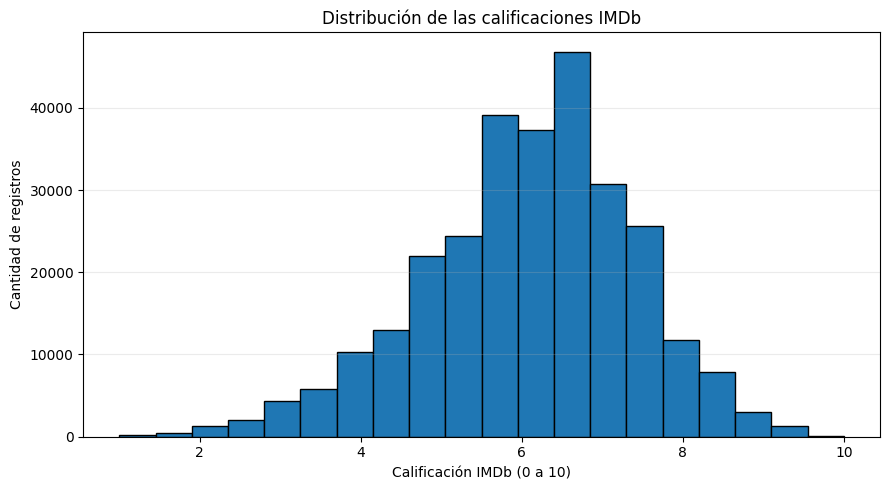

In [32]:
# ============================================================
# 30.3.1 HISTOGRAMA: DISTRIBUCIÓN DE CALIFICACIONES IMDb
# ============================================================

calificaciones = pd.to_numeric(df_eda["averageRating"], errors="coerce").dropna()
if calificaciones.empty:
    print("No hay calificaciones IMDb válidas para graficar.")
else:
    plt.figure(figsize=(9, 5))
    plt.hist(calificaciones, bins=20, edgecolor="black")
    plt.title("Distribución de las calificaciones IMDb")
    plt.xlabel("Calificación IMDb (0 a 10)")
    plt.ylabel("Cantidad de registros")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

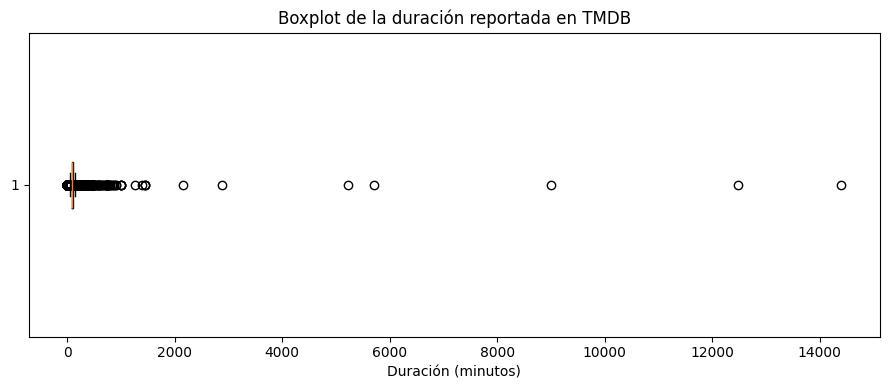

DIAGNÓSTICO DE POSIBLES OUTLIERS EN DURACIÓN
Q1: 81.00 minutos
Q3: 104.00 minutos
IQR: 23.00 minutos
Límite inferior (Q1 - 1.5×IQR): 46.50 minutos
Límite superior (Q3 + 1.5×IQR): 138.50 minutos
Valores fuera de los límites: 13,787
Valores por encima del límite superior: 11,704
Decisión: se conservan en esta etapa y se reportan para revisión; un valor extremo no demuestra por sí solo que sea erróneo.


In [33]:
# ============================================================
# 30.3.2 BOXPLOT: DISPERSIÓN Y POSIBLES VALORES EXTREMOS DE DURACIÓN
# ============================================================

duraciones = pd.to_numeric(df_eda["runtime"], errors="coerce").dropna().astype(float)
if duraciones.empty:
    print("No hay duraciones válidas para graficar.")
else:
    plt.figure(figsize=(9, 4))
    plt.boxplot(duraciones, vert=False, showfliers=True)
    plt.title("Boxplot de la duración reportada en TMDB")
    plt.xlabel("Duración (minutos)")
    plt.tight_layout()
    plt.show()
    plt.close()

    # Regla de 1.5 × IQR para señalar posibles valores extremos, sin eliminarlos.
    q1_runtime = float(duraciones.quantile(0.25))
    q3_runtime = float(duraciones.quantile(0.75))
    iqr_runtime = q3_runtime - q1_runtime
    limite_inferior_runtime = q1_runtime - 1.5 * iqr_runtime
    limite_superior_runtime = q3_runtime + 1.5 * iqr_runtime
    outliers_runtime = duraciones[
        (duraciones < limite_inferior_runtime)
        | (duraciones > limite_superior_runtime)
    ]
    outliers_superiores_runtime = duraciones[
        duraciones > limite_superior_runtime
    ]

    print("DIAGNÓSTICO DE POSIBLES OUTLIERS EN DURACIÓN")
    print("============================================")
    print(f"Q1: {q1_runtime:.2f} minutos")
    print(f"Q3: {q3_runtime:.2f} minutos")
    print(f"IQR: {iqr_runtime:.2f} minutos")
    print(f"Límite inferior (Q1 - 1.5×IQR): {limite_inferior_runtime:.2f} minutos")
    print(f"Límite superior (Q3 + 1.5×IQR): {limite_superior_runtime:.2f} minutos")
    print(f"Valores fuera de los límites: {len(outliers_runtime):,}")
    print(f"Valores por encima del límite superior: {len(outliers_superiores_runtime):,}")
    print("Decisión: se conservan en esta etapa y se reportan para revisión; un valor extremo no demuestra por sí solo que sea erróneo.")

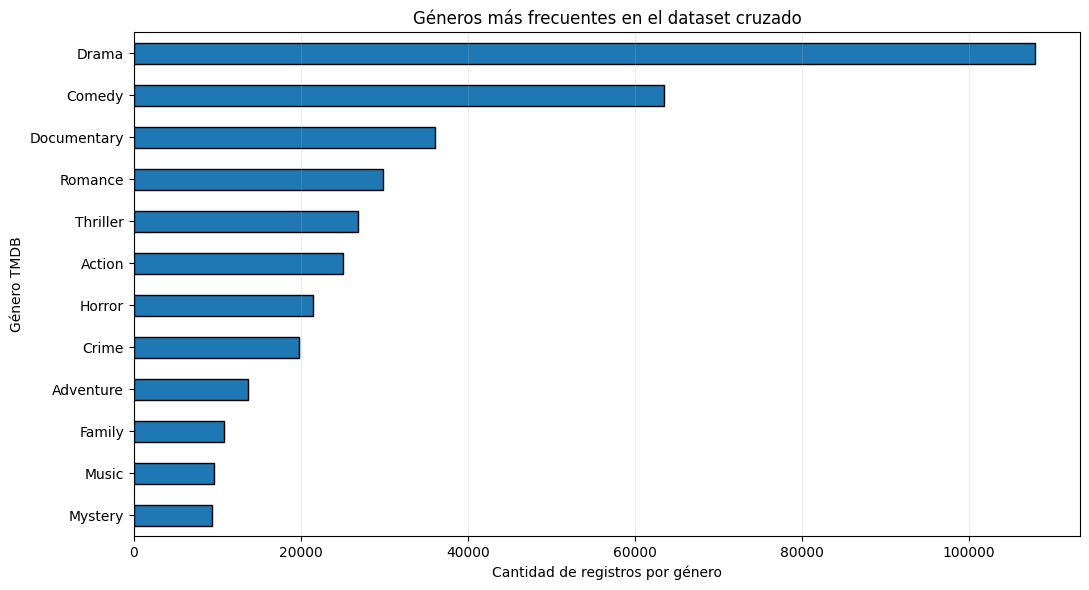

Nota: una misma película puede pertenecer a más de un género; las frecuencias por género no tienen que sumar el total de películas.


In [34]:
# ============================================================
# 30.3.3 GRÁFICO DE BARRAS: GÉNEROS MÁS FRECUENTES
# ============================================================

if frecuencia_generos.empty:
    print("No hay géneros TMDB disponibles para graficar.")
else:
    top_generos = frecuencia_generos.head(12).set_index("género")["cantidad de registros"]
    plt.figure(figsize=(11, 6))
    top_generos.sort_values().plot(kind="barh", edgecolor="black")
    plt.title("Géneros más frecuentes en el dataset cruzado")
    plt.xlabel("Cantidad de registros por género")
    plt.ylabel("Género TMDB")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

print("Nota: una misma película puede pertenecer a más de un género; las frecuencias por género no tienen que sumar el total de películas.")

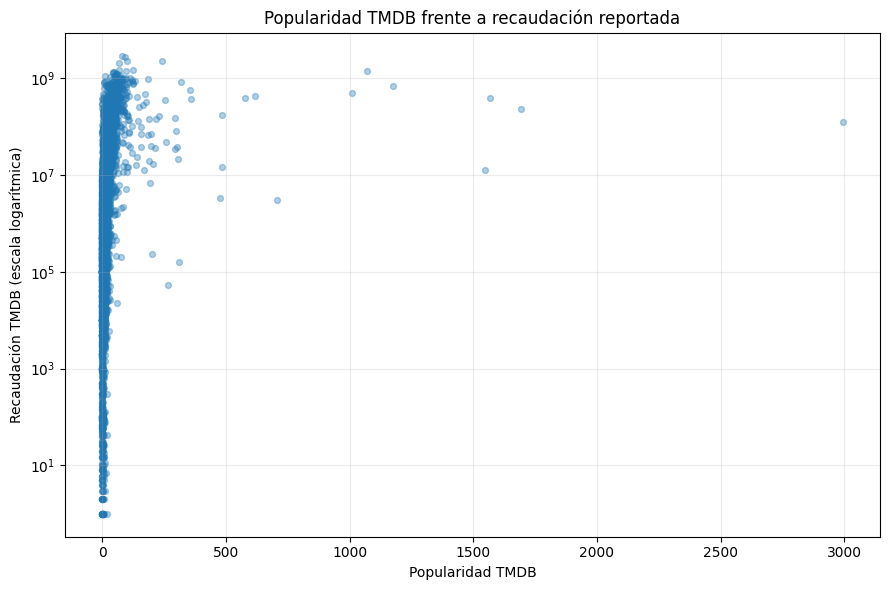

Puntos graficados: 8,000 de 15,853 registros válidos.


In [35]:
# ============================================================
# 30.3.4 SCATTER PLOT: POPULARIDAD VS. RECAUDACIÓN
# ============================================================

columnas_scatter = ["popularity", "revenue"]
df_scatter = df_eda.loc[
    df_eda["revenue"].notna() & df_eda["revenue"].gt(0),
    columnas_scatter
].copy()
df_scatter = df_scatter.dropna()
df_scatter = df_scatter[df_scatter["revenue"] > 0]

if df_scatter.empty:
    print("No hay registros completos con popularidad y recaudación positiva para el scatter plot.")
else:
    # Se limita la cantidad dibujada si hay demasiados puntos; la muestra es reproducible.
    limite_puntos = 8000
    df_scatter_grafico = (
        df_scatter.sample(n=limite_puntos, random_state=42)
        if len(df_scatter) > limite_puntos
        else df_scatter
    )
    plt.figure(figsize=(9, 6))
    plt.scatter(
        df_scatter_grafico["popularity"],
        df_scatter_grafico["revenue"],
        alpha=0.35,
        s=18
    )
    plt.yscale("log")
    plt.title("Popularidad TMDB frente a recaudación reportada")
    plt.xlabel("Popularidad TMDB")
    plt.ylabel("Recaudación TMDB (escala logarítmica)")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()
    print(f"Puntos graficados: {len(df_scatter_grafico):,} de {len(df_scatter):,} registros válidos.")

## 30.4 Comparación de recaudación por género

La frecuencia de un género no significa necesariamente que sus películas tengan mayor éxito en taquilla. Para comparar los géneros se revisa la **mediana de recaudación positiva reportada**, además de la media y el número de registros disponibles. La mediana ayuda a reducir el efecto de unas pocas películas con recaudaciones extraordinariamente altas.

El gráfico presenta solo los géneros que tienen al menos 30 registros con recaudación positiva. Estos resultados son descriptivos y no demuestran que el género, por sí solo, cause una mayor recaudación.

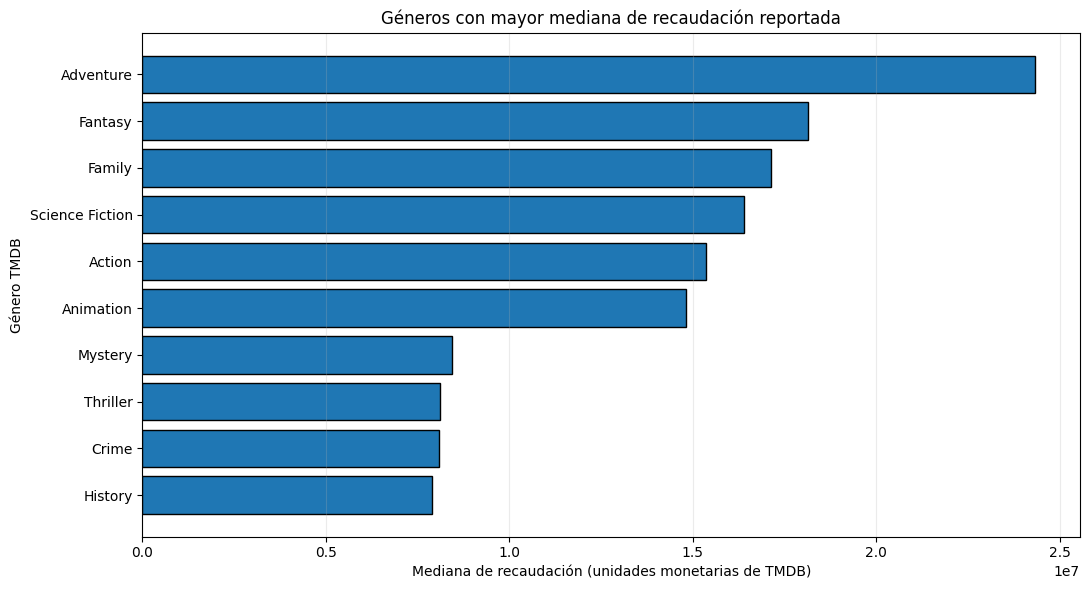

Tabla de referencia: cantidad de registros, media y mediana por género.


,peliculas_con_recaudacion,recaudacion_media,recaudacion_mediana
genero,,,
Adventure,2147,1.351110e+08,24340302.0
Fantasy,1287,1.120632e+08,18129854.0
Family,1449,9.358457e+07,17130489.0
Science Fiction,1265,1.133800e+08,16393000.0
Action,3228,9.149048e+07,15365989.5
Animation,919,1.037656e+08,14817006.0
Mystery,1144,4.150926e+07,8446945.0
Thriller,3297,4.758832e+07,8124257.0
Crime,2059,4.026103e+07,8094616.0


In [36]:
# ============================================================
# 30.4 GRÁFICO COMPLEMENTARIO: MEDIANA DE RECAUDACIÓN POR GÉNERO
# ============================================================

if resumen_recaudacion_genero.empty:
    print("No hay suficientes datos de taquilla por género para construir esta comparación.")
else:
    top_recaudacion_genero = resumen_recaudacion_genero.head(10).sort_values(
        "recaudacion_mediana", ascending=True
    )
    plt.figure(figsize=(11, 6))
    plt.barh(
        top_recaudacion_genero.index.astype(str),
        top_recaudacion_genero["recaudacion_mediana"],
        edgecolor="black"
    )
    plt.title("Géneros con mayor mediana de recaudación reportada")
    plt.xlabel("Mediana de recaudación (unidades monetarias de TMDB)")
    plt.ylabel("Género TMDB")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close()

    print("Tabla de referencia: cantidad de registros, media y mediana por género.")
    display(resumen_recaudacion_genero.head(10).round(2))

## 30.5 Historia de hallazgos

La guía solicita entre 4 y 5 hallazgos que conecten una cifra concreta con la pregunta de negocio. Para no inventar resultados ni fijar cifras que puedan cambiar si se actualizan las fuentes, la siguiente celda redacta **cinco hallazgos a partir de las estadísticas calculadas en este mismo notebook**. La celda genera texto con formato Markdown para que se lea como una historia de resultados.

In [37]:
# ============================================================
# 30.5 HISTORIA DE HALLAZGOS BASADA EN LOS RESULTADOS REALES
# ============================================================

hallazgos_eda = []

# Hallazgo 1: cobertura de la recaudación.
porcentaje_sin_recaudacion = 100 - porcentaje_recaudacion
hallazgos_eda.append(
    f"**1. Cobertura de los datos de taquilla.** La base contiene **{filas_eda:,} registros**, "
    f"pero solo **{filas_con_recaudacion:,} ({porcentaje_recaudacion:.2f}%)** tienen una recaudación "
    f"positiva reportada; el **{porcentaje_sin_recaudacion:.2f}%** restante no tiene una recaudación "
    "positiva disponible para esta comparación. Por eso, los resultados de taquilla deben interpretarse "
    "con cautela: las películas con ingresos reportados podrían no representar a todo el catálogo."
)

# Hallazgo 2: media frente a mediana de calificación IMDb.
if "averageRating" in matriz_numerica.columns:
    ratings_eda = matriz_numerica["averageRating"].dropna()
else:
    ratings_eda = pd.Series(dtype=float)
if not ratings_eda.empty:
    media_rating_eda = float(ratings_eda.mean())
    mediana_rating_eda = float(ratings_eda.median())
    diferencia_rating_eda = abs(media_rating_eda - mediana_rating_eda)
    if diferencia_rating_eda <= 0.3:
        lectura_rating = "la media y la mediana son cercanas, lo que indica que el centro de la distribución no cambia mucho al usar una u otra medida"
    elif media_rating_eda > mediana_rating_eda:
        lectura_rating = "la media queda por encima de la mediana, por lo que valores altos elevan el promedio"
    else:
        lectura_rating = "la media queda por debajo de la mediana, por lo que valores bajos reducen el promedio"
    hallazgos_eda.append(
        f"**2. Calificación de las películas.** La media de IMDb es **{media_rating_eda:.2f}/10** y la mediana "
        f"es **{mediana_rating_eda:.2f}/10** (diferencia de **{diferencia_rating_eda:.2f}** puntos): {lectura_rating}. "
        "La calificación puede ayudar a describir la recepción de una película, pero debe contrastarse con la taquilla "
        "antes de usarla para decidir qué programar."
    )
else:
    hallazgos_eda.append(
        "**2. Calificación de las películas.** No hay suficientes calificaciones IMDb válidas para comparar la media y la mediana; se debe revisar la cobertura de este campo antes de interpretar su relación con la taquilla."
    )

# Hallazgo 3: género más frecuente.
if not frecuencia_generos.empty:
    genero_mas_frecuente = str(frecuencia_generos.iloc[0]["género"])
    cantidad_genero_frecuente = int(frecuencia_generos.iloc[0]["cantidad de registros"])
    porcentaje_genero_frecuente = 100 * cantidad_genero_frecuente / len(df_generos) if len(df_generos) else 0
    hallazgos_eda.append(
        f"**3. Género más representado.** El género más frecuente es **{genero_mas_frecuente}**, con **{cantidad_genero_frecuente:,}** "
        f"asignaciones de género ({porcentaje_genero_frecuente:.2f}% de las asignaciones registradas). Esto muestra qué tipo de película "
        "tiene mayor presencia en la base, pero no significa automáticamente que sea el género más taquillero; para eso se necesita la comparación de recaudación."
    )
else:
    hallazgos_eda.append(
        "**3. Género más representado.** No se encontraron géneros TMDB válidos para calcular frecuencias; sin esta información no se puede comparar la presencia de géneros en el catálogo."
    )

# Hallazgo 4: género con mayor mediana de recaudación, con una base mínima.
if not resumen_recaudacion_genero.empty:
    fila_top_genero = resumen_recaudacion_genero.iloc[0]
    nombre_top_genero = str(resumen_recaudacion_genero.index[0])
    mediana_top_genero = float(fila_top_genero["recaudacion_mediana"])
    cantidad_top_genero = int(fila_top_genero["peliculas_con_recaudacion"])
    hallazgos_eda.append(
        f"**4. Recaudación por género.** Entre los géneros con al menos 30 películas con recaudación positiva reportada, **{nombre_top_genero}** "
        f"presenta la mayor mediana de recaudación (**{mediana_top_genero:,.0f}**, con **{cantidad_top_genero:,}** registros). Es un candidato para estudiar con más detalle, "
        "pero la conclusión solo es válida para las películas con taquilla reportada y no prueba que el género cause ese resultado."
    )
else:
    hallazgos_eda.append(
        "**4. Recaudación por género.** Ningún género reunió al menos 30 registros con recaudación positiva reportada; la información disponible no permite comparar géneros de forma suficientemente estable con ese umbral."
    )

# Hallazgo 5: asociación entre popularidad/calificación y recaudación.
if (
    not df_correlacion.empty
    and "revenue" in df_correlacion.columns
    and ("popularity" in df_correlacion.columns or "averageRating" in df_correlacion.columns)
):
    correlaciones_hallazgo = df_correlacion.corr(method="spearman")
    partes_correlacion = []
    for variable, etiqueta in [
        ("popularity", "popularidad"),
        ("averageRating", "calificación IMDb")
    ]:
        if variable in correlaciones_hallazgo.columns:
            valor_corr = correlaciones_hallazgo.loc[variable, "revenue"]
            if pd.isna(valor_corr):
                partes_correlacion.append(f"no se pudo calcular la asociación con {etiqueta}")
            else:
                magnitud = abs(float(valor_corr))
                if magnitud < 0.20:
                    fuerza = "débil"
                elif magnitud < 0.40:
                    fuerza = "moderada"
                elif magnitud < 0.60:
                    fuerza = "marcada"
                else:
                    fuerza = "fuerte"
                direccion = "positiva" if valor_corr > 0 else "negativa" if valor_corr < 0 else "nula"
                partes_correlacion.append(
                    f"la asociación entre {etiqueta} y recaudación es {direccion} y {fuerza} (Spearman = {float(valor_corr):.3f})"
                )
    resumen_corr = "; mientras que ".join(partes_correlacion) if partes_correlacion else "no se pudieron calcular asociaciones con las variables disponibles"
    hallazgos_eda.append(
        f"**5. Popularidad y calificación frente a taquilla.** En las películas con recaudación positiva reportada, {resumen_corr}. "
        "Estas asociaciones sirven para orientar el análisis, pero no demuestran causalidad ni garantizan la demanda futura en un cine específico."
    )
else:
    hallazgos_eda.append(
        "**5. Popularidad y calificación frente a taquilla.** No hay suficientes registros completos para calcular las correlaciones de Spearman; primero debe mejorarse la cobertura de recaudación o de las variables comparadas."
    )

# Mostrar exactamente cinco hallazgos redactados en lenguaje natural.
texto_hallazgos = "## Hallazgos del análisis exploratorio\n\n" + "\n\n".join(
    f"{i}. {hallazgo.split('. ', 1)[1] if '. ' in hallazgo else hallazgo}"
    for i, hallazgo in enumerate(hallazgos_eda, start=1)
)
# Mantener los encabezados en negrita y la numeración con formato Markdown.
texto_hallazgos = "## Hallazgos del análisis exploratorio\n\n" + "\n\n".join(
    f"{hallazgo}" for hallazgo in hallazgos_eda
)
display(Markdown(texto_hallazgos))

## Hallazgos del análisis exploratorio

**1. Cobertura de los datos de taquilla.** La base contiene **287,639 registros**, pero solo **15,853 (5.51%)** tienen una recaudación positiva reportada; el **94.49%** restante no tiene una recaudación positiva disponible para esta comparación. Por eso, los resultados de taquilla deben interpretarse con cautela: las películas con ingresos reportados podrían no representar a todo el catálogo.

**2. Calificación de las películas.** La media de IMDb es **6.06/10** y la mediana es **6.20/10** (diferencia de **0.14** puntos): la media y la mediana son cercanas, lo que indica que el centro de la distribución no cambia mucho al usar una u otra medida. La calificación puede ayudar a describir la recepción de una película, pero debe contrastarse con la taquilla antes de usarla para decidir qué programar.

**3. Género más representado.** El género más frecuente es **Drama**, con **107,917** asignaciones de género (25.99% de las asignaciones registradas). Esto muestra qué tipo de película tiene mayor presencia en la base, pero no significa automáticamente que sea el género más taquillero; para eso se necesita la comparación de recaudación.

**4. Recaudación por género.** Entre los géneros con al menos 30 películas con recaudación positiva reportada, **Adventure** presenta la mayor mediana de recaudación (**24,340,302**, con **2,147** registros). Es un candidato para estudiar con más detalle, pero la conclusión solo es válida para las películas con taquilla reportada y no prueba que el género cause ese resultado.

**5. Popularidad y calificación frente a taquilla.** En las películas con recaudación positiva reportada, la asociación entre popularidad y recaudación es positiva y fuerte (Spearman = 0.707); mientras que la asociación entre calificación IMDb y recaudación es positiva y débil (Spearman = 0.181). Estas asociaciones sirven para orientar el análisis, pero no demuestran causalidad ni garantizan la demanda futura en un cine específico.